In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

hazy_gray = cv.imread("hazy.png", cv.IMREAD_GRAYSCALE)
hazy_color_rgb = cv.cvtColor(cv.imread("hazy_color.png"), cv.COLOR_BGR2RGB)

In [2]:
# Helper methods

def plot_histogram_cdf(axis, histogram, cdf, color_1="tab:red", color_2="tab:blue"):
    axis.set_xlabel("Pixel intensity")
    axis.set_ylabel("Pixel count", color=color_1)
    axis.plot(histogram, color=color_1)
    axis.tick_params(axis="y", labelcolor=color_1)

    axis_2 = axis.twinx()
    axis_2.set_ylabel("CDF Distribution", color=color_2)
    axis_2.plot(cdf, color=color_2)
    axis_2.tick_params(axis="y", labelcolor=color_2)


def plot_img_with_graphs(img_1, title_1, img_2, title_2):
    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

    ax[0, 0].imshow(img_1, cmap="gray")
    ax[0, 0].set_title(title_1)

    ax[0, 1].imshow(img_2, cmap="gray")
    ax[0, 1].set_title(title_2)

    img_1_hist = np.bincount(img_1.ravel())
    img_2_hist = np.bincount(img_2.ravel())

    img_1_cdf = img_1_hist.cumsum()
    img_2_cdf = img_2_hist.cumsum()

    plot_histogram_cdf(ax[1, 0], img_1_hist, img_1_cdf)
    plot_histogram_cdf(ax[1, 1], img_2_hist, img_2_cdf)

In [3]:
## Compare the three methods of getting histograms (counts)
np_bin_counts = np.bincount(hazy_gray.ravel(), minlength=256)
np_hist_counts, np_hist_edges = np.histogram(hazy_gray, bins=256, range=(0, 256))
cv_hist_counts = cv.calcHist([hazy_gray], [0], None, [256], [0, 256])

### Assert that the three histogram computations are equal to each other
assert np.array_equal(np_bin_counts, np_hist_counts)
assert np.array_equal(np_bin_counts, cv_hist_counts)
assert np.array_equal(np_hist_counts, cv_hist_counts)

### Assert that for each histogram computation, it equals h * w of the image
hazy_gray_h, hazy_gray_w = hazy_gray.shape
hazy_gray_pixel_count = hazy_gray_h * hazy_gray_w

assert np_bin_counts.sum() == np_hist_counts.sum() == cv_hist_counts.sum() == hazy_gray_pixel_count

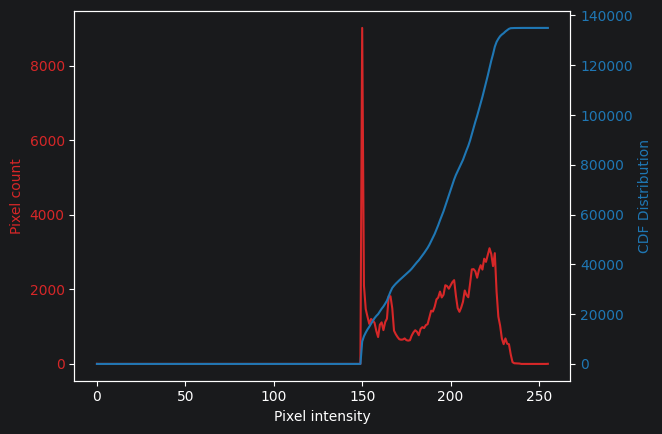

In [4]:
## Calculate the Cumulative Frequency Distribution (CDF) -> Using `np_bin_counts`
hazy_gray_cdf = np_bin_counts.cumsum()

fig, ax = plt.subplots()
plot_histogram_cdf(ax, np_bin_counts, hazy_gray_cdf)

1. The image staying at 0 till the 150 mark tells me that the image is washed out, because all pixel values sit between 150 and 256 levels. Low contrast
2. I cannot see the tiny bars at 0 and 255 yet, but I believe that those are the brightest and the darkest spots. Currently it appears the image doesn't have a truly bright and/or truly dark portion

In [5]:
## Normalize the image (min_max)
hazy_norm = cv.normalize(hazy_gray, None, 0, 255, cv.NORM_MINMAX)

print(f"""Image Dimensions:
Minimum pixel: {hazy_norm.min()}
Maximum pixel: {hazy_norm.max()}
""")

assert np.array_equal(hazy_gray, hazy_norm)

Image Dimensions:
Minimum pixel: 0
Maximum pixel: 255



The array is the same because the image already has a 0px dark area and a 255px bright area. So, normalizing using minmax won't work.

In [12]:
def manually_equalize_hist(img, should_truncate=False):
    counts = np.bincount(img.ravel(), minlength=256)
    cdf = counts.cumsum()
    cdf_min = cdf[counts > 0][0]
    if should_truncate:
        lut_raw = (cdf - cdf_min) / (img.size - cdf_min) * 255
        lut = lut_raw.astype(np.uint8)
    else:
        lut = np.round((cdf - cdf_min) / (img.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)

    return lut[img]


## Compare Automatic vs manual Histogram equalization
auto_hist_equ = cv.equalizeHist(hazy_gray)
manual_hist_equ = manually_equalize_hist(hazy_gray)

assert np.array_equal(auto_hist_equ, manual_hist_equ)

## Assert that truncation causes the two equalization approaches to differ
manual_trunc_hist_equ = manually_equalize_hist(hazy_gray, should_truncate=True)
assert not np.array_equal(manual_hist_equ, manual_trunc_hist_equ)

### Assert that truncating pushes a value down
manual_equ_diff = manual_hist_equ.astype(int) - manual_trunc_hist_equ.astype(int)
assert manual_equ_diff.min() >= 0 and manual_equ_diff.max() <= 1 and manual_equ_diff.any()

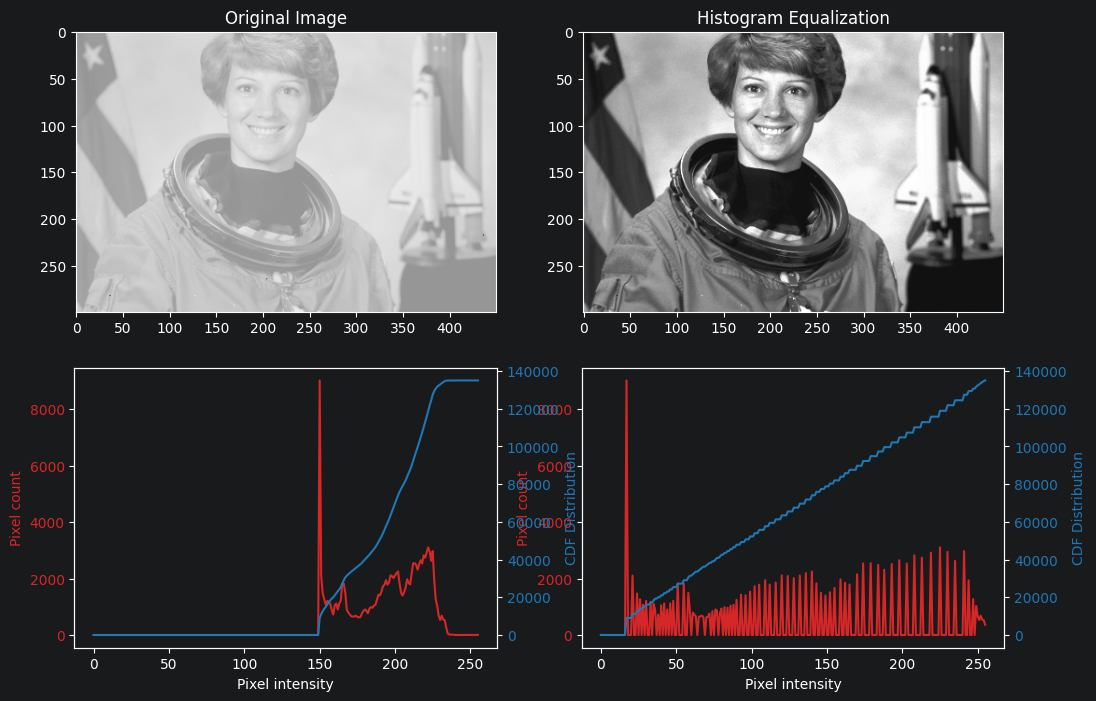

In [7]:
## Plot the 2x2 grid of the original vrs the Histogram equalization and their histogram vs CDF distribution
plot_img_with_graphs(
        img_1=hazy_gray,
        title_1="Original Image",
        img_2=auto_hist_equ,
        title_2="Histogram Equalization"
)

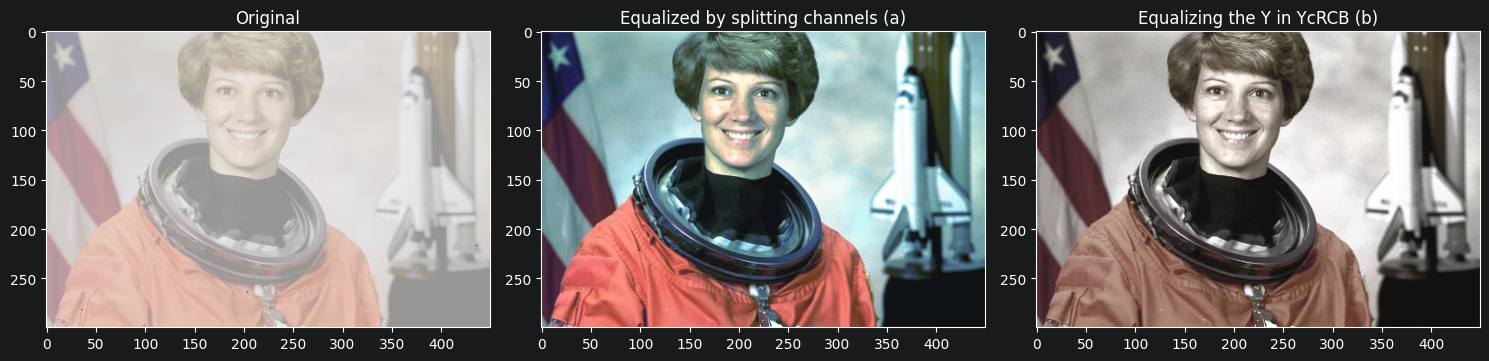

In [8]:
def equalize_by_splitting(img_rgb):
    red_channel_eq = cv.equalizeHist(img_rgb[:, :, 0])
    green_channel_eq = cv.equalizeHist(img_rgb[:, :, 1])
    blue_channel_eq = cv.equalizeHist(img_rgb[:, :, 2])

    return np.dstack([red_channel_eq, green_channel_eq, blue_channel_eq])


def equalize_with_ycrcb(img_rgb):
    ycrcb = cv.cvtColor(img_rgb, cv.COLOR_RGB2YCrCb)
    ycrcb[:, :, 0] = cv.equalizeHist(ycrcb[:, :, 0])

    return cv.cvtColor(ycrcb, cv.COLOR_YCrCb2RGB)


split_channel_equ = equalize_by_splitting(hazy_color_rgb)
ycrcb_equ = equalize_with_ycrcb(hazy_color_rgb)

fig, (plt_1, plt_2, plt_3) = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

plt_1.imshow(hazy_color_rgb, cmap="gray")
plt_1.set_title("Original")

plt_2.imshow(split_channel_equ, cmap="gray")
plt_2.set_title("Equalized by splitting channels (a)")

plt_3.imshow(ycrcb_equ, cmap="gray")
plt_3.set_title("Equalizing the Y in YcRCB (b)")

fig.tight_layout()

By splitting each channel and equalizing, each channel is given a different non-linear curve, so the balance between the colours shift. In this scenario, the background wall and some parts of her hair appear shifted towards blue.

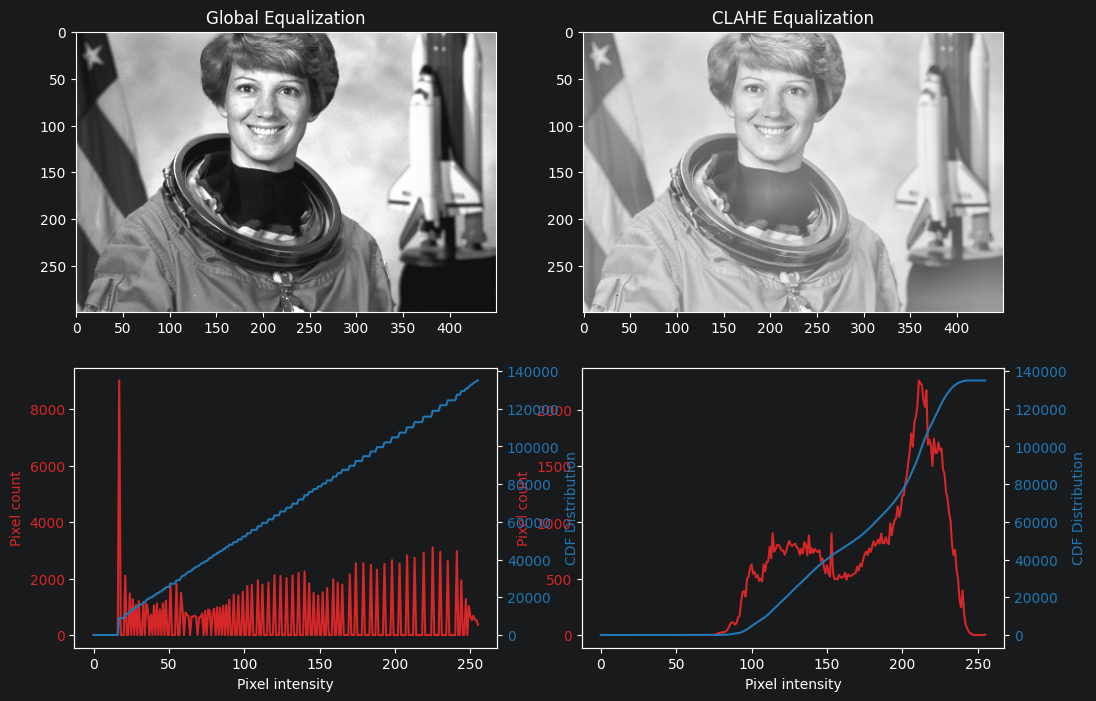

In [9]:
## CLAHE application on the gray image

clahe_equ = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hazy_gray)

plot_img_with_graphs(
        img_1=auto_hist_equ,
        title_1="Global Equalization",
        img_2=clahe_equ,
        title_2="CLAHE Equalization"
)

CLAHE breaks the image into tiles and equalizes them separately. This is great for images that may have a high dynamic range